In [12]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("/Users/jasleenkaur/markovate-assessment/data/raw/bank.csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (11162, 17)


In [5]:
X = df.drop(columns = ["deposit", "duration"])
Y = df["deposit"].map({"no": 0, "yes": 1})

print("Features Shape:", X.shape)
print("Target Shape:", Y.shape)

Features Shape: (11162, 15)
Target Shape: (11162,)


In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state = 42,
    stratify = Y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", Y_train.shape)
print("Testing Target:", Y_test.shape)

Training Features: (8929, 15)
Testing Features: (2233, 15)
Training Target: (8929,)
Testing Target: (2233,)


In [8]:
numerical_features = X.select_dtypes(include = ["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include = ["object"]).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [9]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

logistic_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown = "ignore"), categorical_features)
])

random_forest_preprocessor = ColumnTransformer([
    ("num", "passthrough", numerical_features),
    ("cat", OneHotEncoder(handle_unknown = "ignore"), categorical_features)
])

In [10]:
df["age_group"] = pd.cut(
    df["age"],
    bins = [18, 30, 40, 50, 60, 100],
    labels = ["18-30", "31-40", "41-50", "51-60", "60+"],
    include_lowest = True
)

age_subscription = df.groupby("age_group", observed = False)["deposit"].apply(
    lambda x : (x == "yes").mean() * 100
)

print(age_subscription)

age_group
18-30    57.050324
31-40    43.266476
41-50    40.825321
51-60    43.602151
60+      82.160393
Name: deposit, dtype: float64


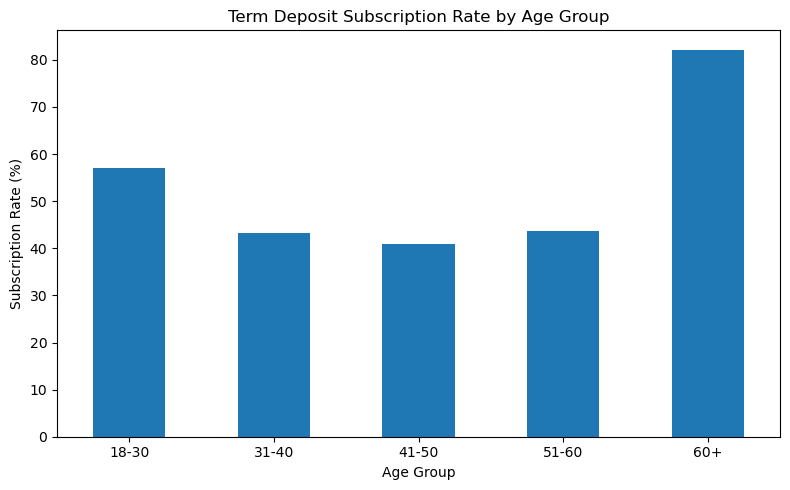

In [13]:
age_subscription.plot(kind = "bar", figsize = (8, 5))
plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

In [14]:
job_subscription = df.groupby("job")["deposit"].apply(
    lambda x : (x == "yes").mean() * 100
)

print(job_subscription.sort_values(ascending = False))

job
student          74.722222
retired          66.323907
unemployed       56.582633
management       50.701481
unknown          48.571429
admin.           47.301349
self-employed    46.172840
technician       46.077894
services         39.978332
housemaid        39.781022
entrepreneur     37.500000
blue-collar      36.419753
Name: deposit, dtype: float64


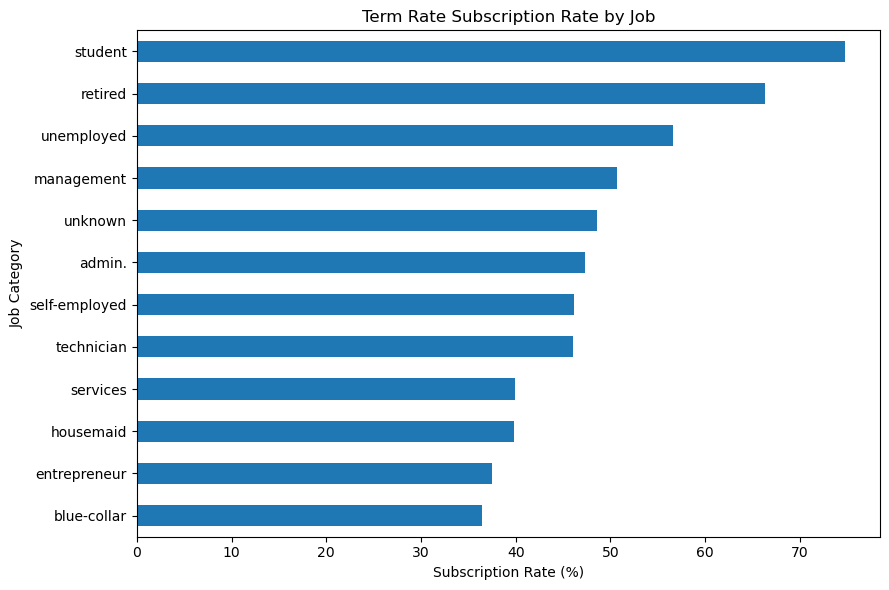

In [15]:
job_subscription.sort_values().plot(
    kind = "barh",
    figsize = (9, 6)
)

plt.title("Term Rate Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

In [16]:
df["balance_group"] = pd.qcut(
    df["balance"],
    q = 4,
    duplicates = "drop"
)

balance_subscription = df.groupby(
    "balance_group",
    observed = False
)["deposit"].apply(
    lambda x : (x == "yes").mean() * 100
)

print(balance_subscription)

balance_group
(-6847.001, 122.0]    35.959885
(122.0, 550.0]        46.219993
(550.0, 1708.0]       49.874507
(1708.0, 81204.0]     57.491039
Name: deposit, dtype: float64


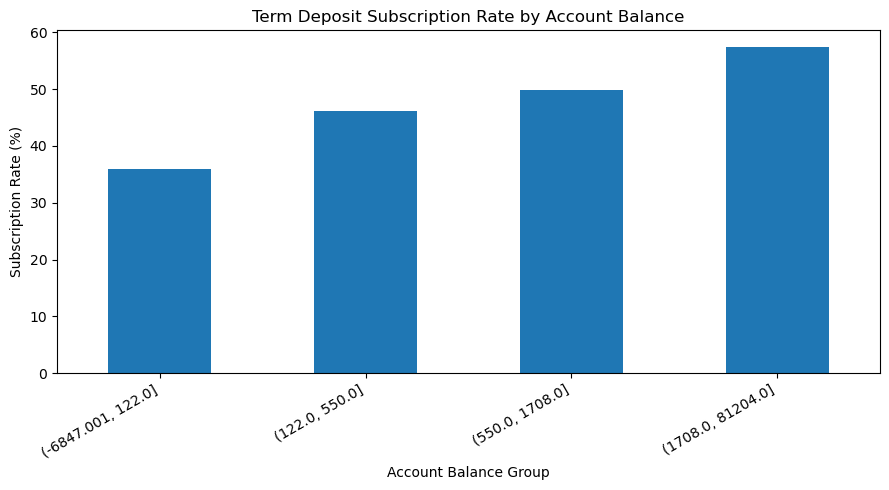

In [17]:
balance_subscription.plot(
    kind = "bar",
    figsize = (9,5)
)

plt.title("Term Deposit Subscription Rate by Account Balance")
plt.xlabel("Account Balance Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation = 30, ha = "right")
plt.tight_layout()
plt.show()

In [18]:
month_subscription = df.groupby("month")["deposit"].apply(
    lambda x : (x == "yes").mean() * 100
)

print(month_subscription)

month
apr    62.513543
aug    45.292956
dec    90.909091
feb    56.829897
jan    41.279070
jul    41.413474
jun    44.680851
mar    89.855072
may    32.754958
nov    42.735949
oct    82.397959
sep    84.326019
Name: deposit, dtype: float64


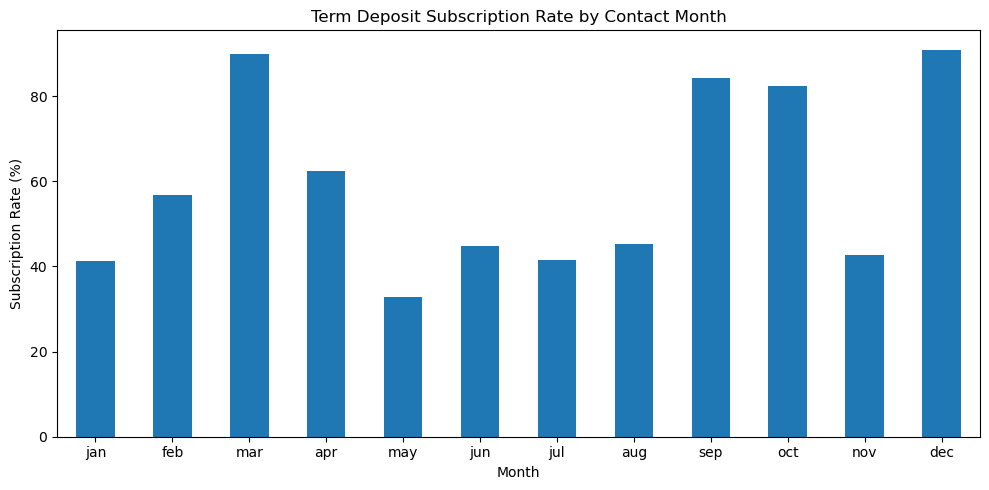

In [19]:
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_subscription = month_subscription.reindex(month_order)

month_subscription.plot(kind = "bar", figsize=(10,5))
plt.title("Term Deposit Subscription Rate by Contact Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

In [20]:
poutcome_subscription = df.groupby("poutcome")["deposit"].apply(
    lambda x : (x == "yes").mean() * 100
)

print(poutcome_subscription.sort_values(ascending=False))

poutcome
success    91.316527
other      57.169460
failure    50.325733
unknown    40.667788
Name: deposit, dtype: float64


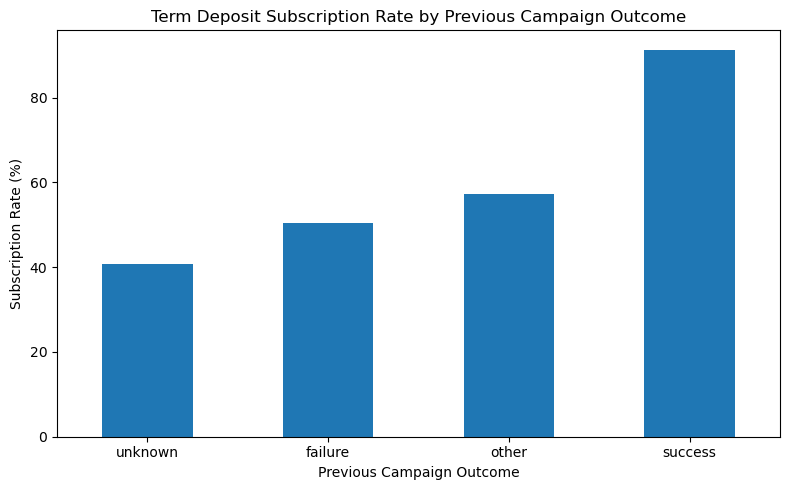

In [21]:
poutcome_subscription.sort_values().plot(
    kind = "bar",
    figsize = (8,5)
)

plt.title("Term Deposit Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

In [22]:
print("Customers by job:")
print(df["job"].value_counts())

print("Customers by month:")
print(df["month"].value_counts())

Customers by job:
job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64
Customers by month:
month
may    2824
aug    1519
jul    1514
jun    1222
nov     943
apr     923
feb     776
oct     392
jan     344
sep     319
mar     276
dec     110
Name: count, dtype: int64
